In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('SuperMarket Analysis.csv')

print(df.head())

    Invoice ID Branch       City Customer type  Gender  \
0  579-15-5088      C  Naypyitaw        Member  Female   
1  662-83-6878      B   Mandalay        Member    Male   
2  994-59-5015      C  Naypyitaw        Member  Female   
3  320-69-8296      C  Naypyitaw        Member  Female   
4  388-16-1094      A     Yangon        Normal    Male   

             Product line  Unit price  Quantity  Tax 5%    Sales       Date  \
0      Food and beverages       26.27         6   7.881  165.501  1/12/2019   
1       Sports and travel       31.06         1   1.553   32.613  3/26/2019   
2  Electronic accessories       84.35         2   8.435  177.135  2/11/2019   
3      Food and beverages       88.60         1   4.430   93.030   3/5/2019   
4       Health and beauty       46.44         9  20.898  438.858  2/23/2019   

    Time      Payment    cogs  gross margin percentage  gross income  Rating  
0  11:11  Credit card  157.62                 4.761905         7.881     9.0  
1  11:32      Ewal

In [9]:
df = pd.read_csv('SuperMarket Analysis.csv')
print(df.shape)
print(df.head)
print(df.describe())
print(df.info())

(1000, 17)
<bound method NDFrame.head of       Invoice ID Branch       City Customer type  Gender  \
0    579-15-5088      C  Naypyitaw        Member  Female   
1    662-83-6878      B   Mandalay        Member    Male   
2    994-59-5015      C  Naypyitaw        Member  Female   
3    320-69-8296      C  Naypyitaw        Member  Female   
4    388-16-1094      A     Yangon        Normal    Male   
..           ...    ...        ...           ...     ...   
995  385-91-7651      B   Mandalay        Normal    Male   
996  242-29-1728      B   Mandalay        Member  Female   
997  330-68-9422      A     Yangon        Member    Male   
998  532-17-1426      C  Naypyitaw        Normal  Female   
999  472-33-6190      A     Yangon        Normal    Male   

               Product line  Unit price  Quantity  Tax 5%    Sales       Date  \
0        Food and beverages       26.27         6   7.881  165.501  1/12/2019   
1         Sports and travel       31.06         1   1.553   32.613  3/26/201

Q2. Are there any missing values or duplicate records? If so, identify them.

In [10]:
print(df.isna().sum())

Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Sales                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64


Q3. What is the total sales/revenue generated from all transactions?

In [12]:
total_sales = df["Sales"].sum()

print("Total Sales:", total_sales)

Total Sales: 298462.41599999997


Q4. What is the average transaction value?

In [13]:
average_transaction = df["Sales"].mean()

print("Average Transaction Value:", round(average_transaction, 2))

Average Transaction Value: 298.46


Q5. Which product line generated the highest total sales?

In [14]:
product_sales = df.groupby("Product line")["Sales"].sum()

print(product_sales)

Product line
Electronic accessories    64194.2175
Fashion accessories       43328.2920
Food and beverages        43277.8080
Health and beauty         55203.8445
Home and lifestyle        42061.7715
Sports and travel         50396.4825
Name: Sales, dtype: float64


In [15]:
highest_product = product_sales.idxmax()
highest_product_sales = product_sales.max()

print("Highest Selling Product Line:", highest_product)
print("Total Sales:", round(highest_product_sales, 2))

Highest Selling Product Line: Electronic accessories
Total Sales: 64194.22


Q6. Which product line had the highest quantity sold?

In [16]:
product_quantity = df.groupby("Product line")["Quantity"].sum()

print(product_quantity)
highest_quantity_product = product_quantity.idxmax()
highest_quantity = product_quantity.max()

print("Product Line with Highest Quantity:", highest_quantity_product)
print("Quantity Sold:", highest_quantity)

Product line
Electronic accessories    1038
Fashion accessories        805
Food and beverages         916
Health and beauty          983
Home and lifestyle         832
Sports and travel          837
Name: Quantity, dtype: int64
Product Line with Highest Quantity: Electronic accessories
Quantity Sold: 1038


Q7. Which branch generated the highest total sales?

In [17]:
branch_sales = df.groupby("Branch")["Sales"].sum()

print(branch_sales)

Branch
A    107049.558
B     94243.590
C     97169.268
Name: Sales, dtype: float64


In [18]:
best_branch = branch_sales.idxmax()
best_branch_sales = branch_sales.max()

print("Best Performing Branch:", best_branch)
print("Total Sales:", round(best_branch_sales, 2))

Best Performing Branch: A
Total Sales: 107049.56


Q8. Which customer type generated the highest total sales?

In [19]:
customer_sales = df.groupby("Customer type")["Sales"].sum()

print(customer_sales)

Customer type
Member    148329.699
Normal    150132.717
Name: Sales, dtype: float64


In [20]:
best_customer_type = customer_sales.idxmax()
best_customer_sales = customer_sales.max()

print("Highest Spending Customer Type:", best_customer_type)
print("Total Sales:", round(best_customer_sales, 2))

Highest Spending Customer Type: Normal
Total Sales: 150132.72


Q9. Which payment method was used most frequently?

In [21]:
payment_counts = df["Payment"].value_counts()

print(payment_counts)

Payment
Cash           370
Ewallet        331
Credit card    299
Name: count, dtype: int64


In [22]:
most_used_payment = payment_counts.idxmax()
frequency = payment_counts.max()

print("Most Used Payment Method:", most_used_payment)
print("Number of Transactions:", frequency)

Most Used Payment Method: Cash
Number of Transactions: 370


Q10. Which gender generated the highest total sales?

In [23]:
gender_sales = df.groupby("Gender")["Sales"].sum()

print(gender_sales)

Gender
Female    154917.483
Male      143544.933
Name: Sales, dtype: float64


In [24]:
highest_gender = gender_sales.idxmax()
highest_gender_sales = gender_sales.max()

print("Gender with Highest Sales:", highest_gender)
print("Total Sales:", round(highest_gender_sales, 2))

Gender with Highest Sales: Female
Total Sales: 154917.48


Q11. Which month had the highest total sales?

In [25]:
df["Date"] = pd.to_datetime(df["Date"])

In [26]:
df["Month"] = df["Date"].dt.month_name()

In [27]:
monthly_sales = df.groupby("Month")["Sales"].sum()

print(monthly_sales)

Month
February     98976.3285
January      93508.6845
March       105977.4030
Name: Sales, dtype: float64


In [28]:
month_order = ["January", "February", "March"]

monthly_sales = df.groupby("Month")["Sales"].sum().reindex(month_order)

print(monthly_sales)

Month
January      93508.6845
February     98976.3285
March       105977.4030
Name: Sales, dtype: float64


In [29]:
best_month = monthly_sales.idxmax()
best_month_sales = monthly_sales.max()

print("Best Month:", best_month)
print("Total Sales:", round(best_month_sales, 2))

Best Month: March
Total Sales: 105977.4


In [ ]:
Q12. Which day of the week had the highest sales?

In [30]:
df["Day"] = df["Date"].dt.day_name()

In [31]:
daily_sales = df.groupby("Day")["Sales"].sum()

print(daily_sales)

Day
Friday       50969.5935
Monday       32988.8265
Saturday     61929.7350
Sunday       34565.4330
Thursday     45671.8710
Tuesday      33936.1155
Wednesday    38400.8415
Name: Sales, dtype: float64


In [32]:
best_day = daily_sales.idxmax()
best_day_sales = daily_sales.max()

print("Best Sales Day:", best_day)
print("Total Sales:", round(best_day_sales, 2))

Best Sales Day: Saturday
Total Sales: 61929.74


Q13. Which product line has the highest average transaction value?

In [33]:
average_product_sales = df.groupby("Product line")["Sales"].mean()

print(average_product_sales)

Product line
Electronic accessories    339.651944
Fashion accessories       311.714331
Food and beverages        247.301760
Health and beauty         298.399159
Home and lifestyle        267.909373
Sports and travel         325.138597
Name: Sales, dtype: float64


In [34]:
highest_average_product = average_product_sales.idxmax()
highest_average_value = average_product_sales.max()

print("Product Line with Highest Average Transaction:",
      highest_average_product)

print("Average Transaction Value:",
      round(highest_average_value, 2))

Product Line with Highest Average Transaction: Electronic accessories
Average Transaction Value: 339.65


Q14. Is there a relationship between quantity sold and total sales? Use an appropriate visualization.

In [35]:
quantity_sales_correlation = df["Quantity"].corr(df["Sales"])

print("Correlation:", round(quantity_sales_correlation, 3))

Correlation: 0.795


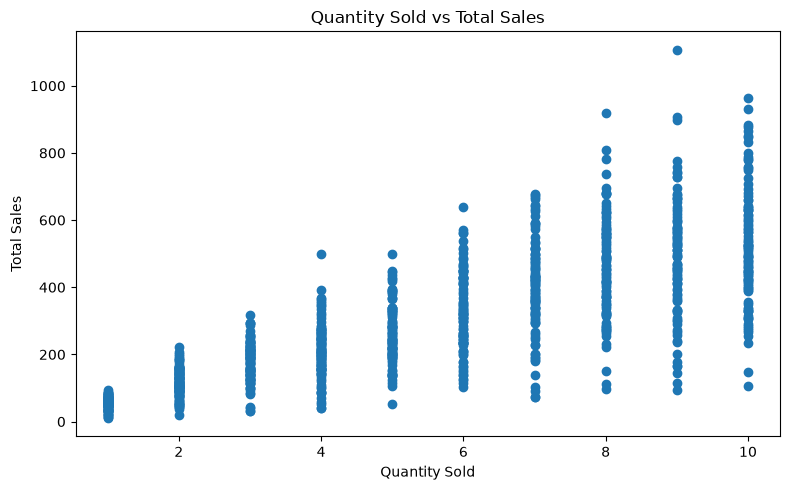

In [36]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Quantity"], df["Sales"])

plt.title("Quantity Sold vs Total Sales")
plt.xlabel("Quantity Sold")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.show()

Q15. Create a correlation heatmap for the numerical variables. Which relationships appear strongest?

In [52]:
numerical_data = df.select_dtypes(include="number")

In [53]:
correlation_matrix = numerical_data.corr()

print(correlation_matrix)

                         Unit price  Quantity    Tax 5%     Sales      cogs  \
Unit price                 1.000000 -0.051578  0.496373  0.496373  0.496373   
Quantity                  -0.051578  1.000000  0.794866  0.794866  0.794866   
Tax 5%                     0.496373  0.794866  1.000000  1.000000  1.000000   
Sales                      0.496373  0.794866  1.000000  1.000000  1.000000   
cogs                       0.496373  0.794866  1.000000  1.000000  1.000000   
gross margin percentage         NaN       NaN       NaN       NaN       NaN   
gross income               0.496373  0.794866  1.000000  1.000000  1.000000   
Rating                    -0.032476  0.045721  0.013280  0.013280  0.013280   

                         gross margin percentage  gross income    Rating  
Unit price                                   NaN      0.496373 -0.032476  
Quantity                                     NaN      0.794866  0.045721  
Tax 5%                                       NaN      1.000000 

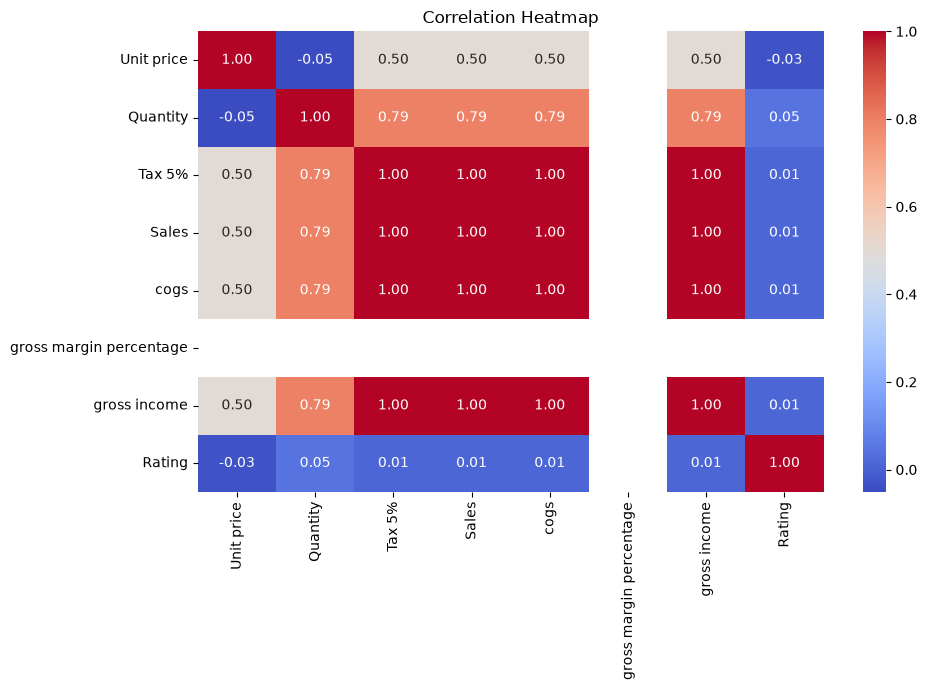

In [40]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

Q16. Identify any potential outliers in total sales or another suitable numerical variable. Explain your finding.

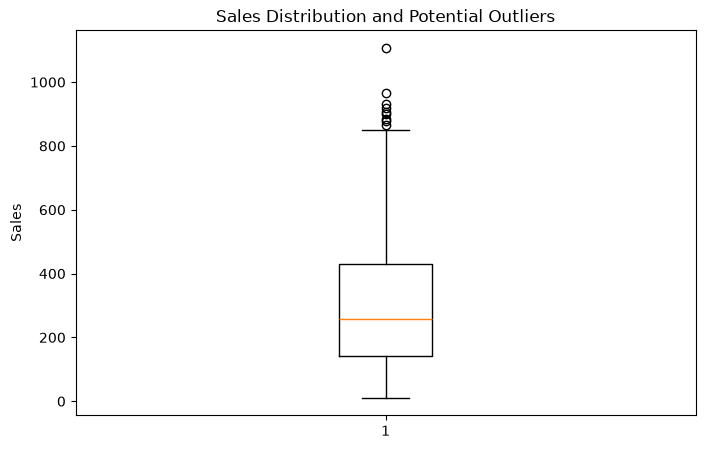

In [41]:
plt.figure(figsize=(8, 5))

plt.boxplot(df["Sales"])

plt.title("Sales Distribution and Potential Outliers")
plt.ylabel("Sales")

plt.show()

In [42]:
Q1 = df["Sales"].quantile(0.25)
Q3 = df["Sales"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 142.20675
Q3: 429.597
IQR: 287.39025
Lower Bound: -288.878625
Upper Bound: 860.682375


In [43]:
outliers = df[
    (df["Sales"] < lower_bound) |
    (df["Sales"] > upper_bound)
]

print("Number of Outliers:", len(outliers))
print(outliers[["Invoice ID", "Product line", "Quantity", "Sales"]])

Number of Outliers: 9
      Invoice ID            Product line  Quantity      Sales
38   928-74-1292  Electronic accessories        10   877.1700
233  669-93-9010       Health and beauty         9  1107.2565
239  284-67-5806  Electronic accessories         9   906.2550
319  113-28-5494  Electronic accessories         9   898.6950
411  341-62-6947       Health and beauty         8   919.2120
424  995-65-1454       Health and beauty        10   866.3550
560  674-55-9747      Food and beverages        10   931.1400
564  998-67-5312     Fashion accessories        10   883.4700
908  793-36-6567       Sports and travel        10   964.5300


Q17. Create a dashboard-style set of at least four visualizations that summarizes supermarket performance.

Chart 1 — Product-line sales

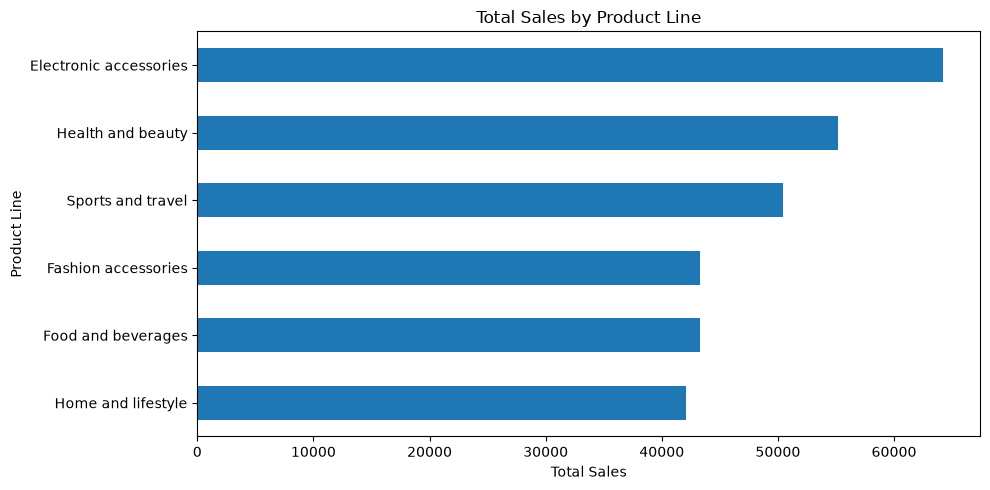

In [44]:
plt.figure(figsize=(10, 5))

product_sales.sort_values().plot(kind="barh")

plt.title("Total Sales by Product Line")
plt.xlabel("Total Sales")
plt.ylabel("Product Line")

plt.tight_layout()
plt.show()

Chart 2 — Branch sales

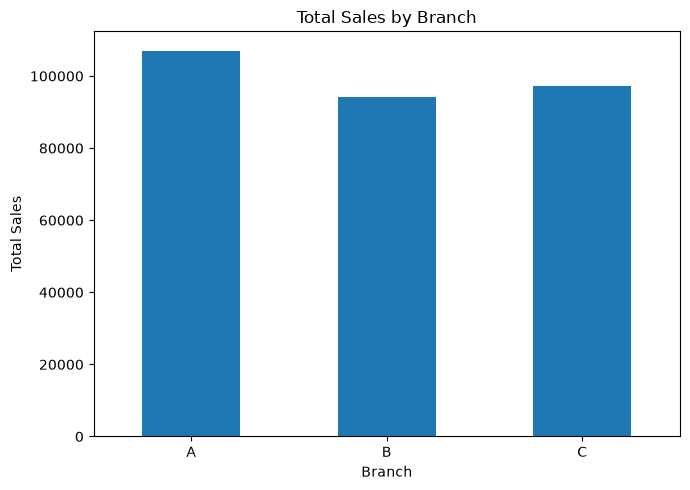

In [45]:
plt.figure(figsize=(7, 5))

branch_sales.plot(kind="bar")

plt.title("Total Sales by Branch")
plt.xlabel("Branch")
plt.ylabel("Total Sales")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

Chart 3 — Monthly sales

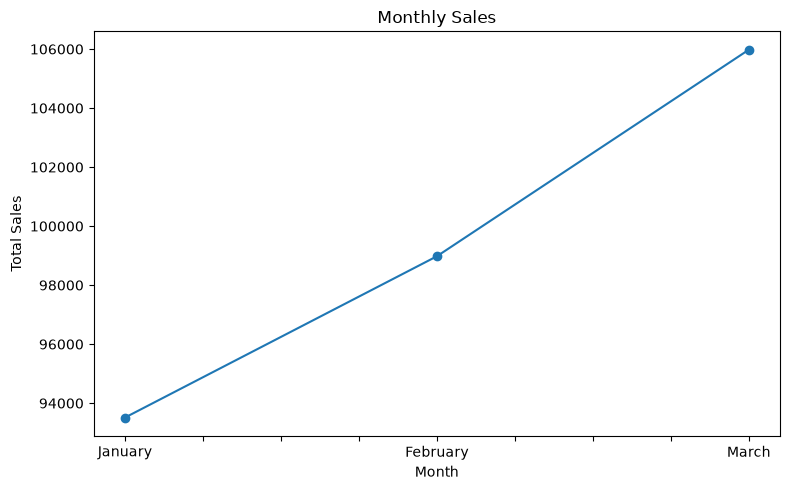

In [46]:
plt.figure(figsize=(8, 5))

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.show()

Chart 4 — Sales distribution

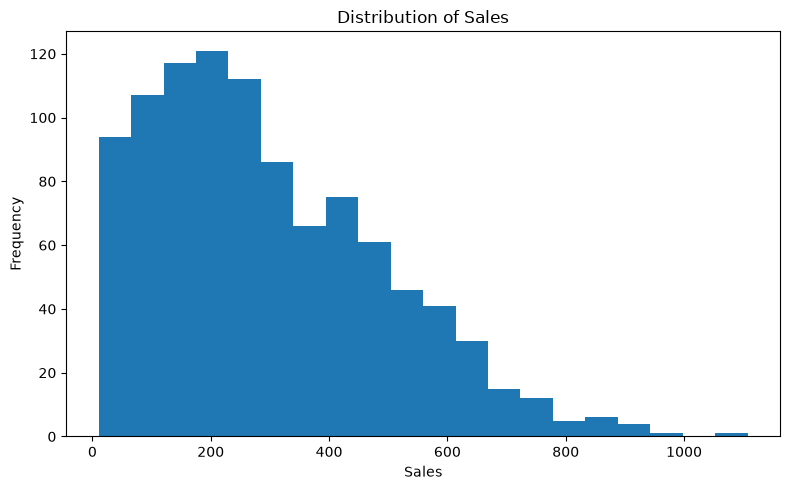

In [47]:
plt.figure(figsize=(8, 5))

plt.hist(df["Sales"], bins=20)

plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

Chart 5 — Quantity vs Sales

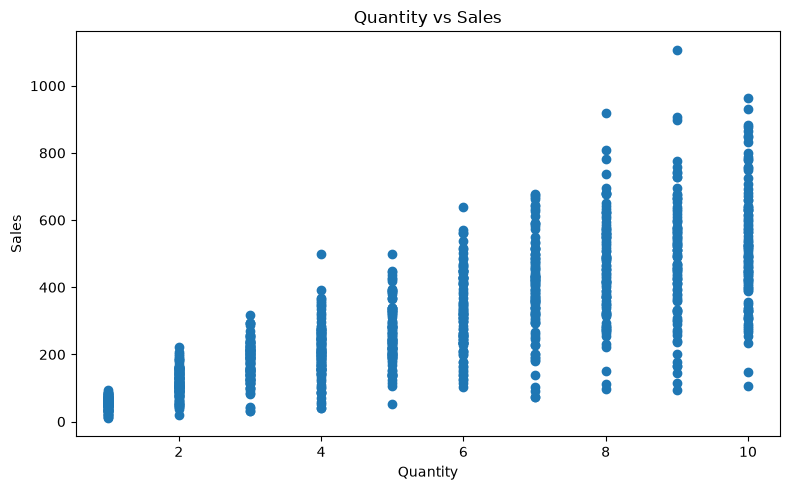

In [48]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Quantity"], df["Sales"])

plt.title("Quantity vs Sales")
plt.xlabel("Quantity")
plt.ylabel("Sales")

plt.tight_layout()
plt.show()

Chart 6 — Customer type sales

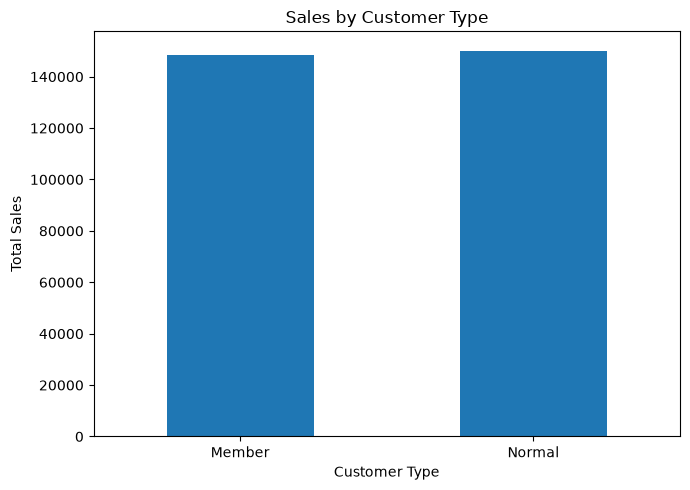

In [49]:
plt.figure(figsize=(7, 5))

customer_sales.plot(kind="bar")

plt.title("Sales by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Total Sales")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

Q18 — Business insights and recommendations

In [50]:
print("===== BUSINESS INSIGHTS =====")

print("1. Highest selling product line:",
      highest_product)

print("2. Best performing branch:",
      best_branch)

print("3. Highest sales month:",
      best_month)

print("4. Highest sales day:",
      best_day)

print("5. Highest spending customer type:",
      best_customer_type)

===== BUSINESS INSIGHTS =====
1. Highest selling product line: Electronic accessories
2. Best performing branch: A
3. Highest sales month: March
4. Highest sales day: Saturday
5. Highest spending customer type: Normal


In [51]:
print("\n===== RECOMMENDATIONS =====")

print("1. Increase stock and promotional activities for the highest-selling product line.")

print("2. Analyze the strategies used by the best-performing branch and apply successful practices to other branches.")

print("3. Develop targeted promotions during the highest-sales periods to maximize revenue.")


===== RECOMMENDATIONS =====
1. Increase stock and promotional activities for the highest-selling product line.
2. Analyze the strategies used by the best-performing branch and apply successful practices to other branches.
3. Develop targeted promotions during the highest-sales periods to maximize revenue.


CONCLUSION

The supermarket sales analysis successfully demonstrated how Python and Pandas can be used to load, clean, analyze, and visualize a real-world dataset. The analysis identified important patterns in sales performance across product lines, branches, customer types, payment methods, gender, and time periods. The visualizations and statistical analysis also helped reveal relationships between variables such as quantity sold and total sales. Overall, the findings provide useful Business Intelligence insights that can support management in making informed decisions, improving sales strategies, managing inventory, and identifying opportunities for business growth. This project also achieved the assignment objectives of performing descriptive and comparative analysis, creating visualizations, interpreting findings, and developing practical recommendations.